# L2: Random Seed 42 Exercises
**City Optimise × DSAI** · Python fundamentals, NumPy, pandas, Matplotlib, PCA & K-Means

- **Part 1 (TOP):** exercises with skeleton code. Fill in every `# TODO`.
- **Part 2 (BOTTOM):** model solutions. Try first, peek later!

All data is generated locally, so no downloads are needed.

---

**Douglas Adams, A Hitchhiker's Guide to the Galaxy**

"All right," said Deep Thought. "The Answer to the Great Question..."
"Yes..!"
"Of Life, the Universe and Everything..." said Deep Thought.
"Yes...!"
"Is..." said Deep Thought, and paused.
"Yes...!"
"Is..."
"Yes...!!!...?"
"Forty-two," said Deep Thought, with infinite majesty and calm.”

In [ ]:
# Setup (run first)
# !pip install numpy pandas matplotlib scikit-learn
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

np.random.seed(42)

---
# PART 1 — Exercises
## Section A: Python & Data Tooling

### Q1. Comprehensions
Given `features`, build a dict `{"f_0": x**2, "f_1": ...}` containing the **squares of the positive values only**, using a single dict comprehension (hint: `enumerate`).

In [ ]:
features = [1.2, -0.5, 3.4, 0.0, 2.0, -1.1]

sq_map = None  # TODO

print(sq_map)  # expected: {'f_0': 1.44, 'f_1': 11.56, 'f_2': 4.0}

None


### Q2. Functions, type hints & error handling
Write `clean_inputs(raw: list[str]) -> list[float]` that converts each string to a float. Values that fail to convert **or** are NaN should be replaced by the **median of the valid values**.

In [ ]:
def clean_inputs(raw: list[str]) -> list[float]:
    valid = []
    # TODO: first pass, collect valid floats (use try/except ValueError, skip NaNs)

    median = None  # TODO

    cleaned = []
    # TODO: second pass, fill in values, imputing the median where needed
    return cleaned

print(clean_inputs(["1.5", "nan", "corrupt", "4.0", "2.5"]))  # expected: [1.5, 2.5, 2.5, 4.0, 2.5]

[]


### Q3. `**kwargs` for hyperparameters
Write `train_model(name, **kwargs)` that returns a string like `"KMeans | lr=0.01 | epochs=10"`, defaulting `lr` to `0.01` and `epochs` to `10` when they are not passed.

In [ ]:
def train_model(name, **kwargs):
    # TODO
    pass

print(train_model("KMeans"))
print(train_model("LinearReg", lr=0.001, epochs=50))

None
None


### Q4. NumPy: slicing & standardisation
1. Split `data` into `X` (all columns but the last) and `y` (last column).
2. Standardise `X` **by hand** (zero mean, unit std **per column**) using `axis=0` and broadcasting.
3. Check your result matches `StandardScaler`.

In [ ]:
data = np.random.randn(100, 4) * [1, 10, 100, 1] + [0, 5, -50, 1]

X = None  # TODO
y = None  # TODO

X_std = None  # TODO: (X - mean) / std

# Check
# print(np.allclose(X_std, StandardScaler().fit_transform(X)))

### Q5. NumPy: a tiny forward pass
Implement one dense layer with ReLU: `out = relu(X @ W + b)`.
- `X` has shape `(32, 3)`, `W` has shape `(3, 2)`, `b` has shape `(2,)`.
- Use `np.maximum` for ReLU (no Python loops). Print the output shape and the fraction of zeros.

In [ ]:
np.random.seed(42)
X_in = np.random.randn(32, 3)
W = np.random.randn(3, 2)
b = np.array([0.5, -0.5])

def relu(z):
    pass  # TODO

out = None  # TODO
# print(out.shape, (out == 0).mean())

### Q6. pandas: wrangling
Using `df` below:
1. Fill missing `age` with the median age.
2. Add `ratio = income / (debt + 1e-5)` and `is_senior` (1 if age ≥ 65 else 0).
3. One-hot encode `city` with `drop_first=True`.
4. Compute mean `income` and total `churn` per `city` (use the **original** `df`, before encoding).

In [ ]:
df = pd.DataFrame({
    "age":    [22, 35, np.nan, 67, 45, np.nan, 71, 29],
    "income": [28e3, 52e3, 61e3, 34e3, 80e3, 45e3, 30e3, 39e3],
    "debt":   [5e3, 12e3, 0, 2e3, 20e3, 8e3, 0, 15e3],
    "city":   ["London", "Leeds", "London", "Bristol", "Leeds", "London", "Bristol", "Leeds"],
    "churn":  [0, 1, 0, 1, 0, 0, 1, 1],
})

# TODO 1

# TODO 2

encoded = None  # TODO 3

summary = None  # TODO 4
# print(summary)

### Q7. Matplotlib: diagnostic plot
Plot `train_loss` and `val_loss` against epochs on the same axes with:
- a legend (upper right), axis labels and a title,
- a dashed grey `axhline` at `y=0.2` labelled "Target",
- an annotation arrow at the epoch where **validation loss is lowest** ("Early stop").

In [ ]:
epochs = np.arange(1, 21)
train_loss = 1.0 * np.exp(-0.2 * epochs) + 0.05
val_loss = 1.0 * np.exp(-0.2 * epochs) + 0.1 + 0.004 * (epochs - 8).clip(0) ** 2

best_epoch = None  # TODO (hint: np.argmin)

# TODO: plotting code

## Section A2: NumPy — Randomness & Distributions
Machine learning is built on random numbers: weight initialisation, train/test splits, bootstrapping, K-Means restarts. These short exercises build intuition for NumPy's random tools using the modern `Generator` API (`np.random.default_rng`).

### N1. Reproducible randomness
1. Create **two** generators with seed `7` and one with seed `8`. Show that the first 3 `.random()` draws of the seed-7 generators are identical, and that seed 8 differs.
2. Using a fresh `rng = np.random.default_rng(42)`, draw: 5 uniform floats in [0, 1); 5 dice rolls (integers 1-6); a random permutation of `np.arange(10)`; 3 names from `names` chosen **without replacement**.
3. In one sentence: why is passing an `rng` object around better than a global `np.random.seed(...)`?

In [ ]:
names = ["Ada", "Grace", "Alan", "Linus", "Margaret", "Guido"]

rng_a = None  # TODO seed 7
rng_b = None  # TODO seed 7
rng_c = None  # TODO seed 8

rng = None      # TODO
uniform = None  # TODO
dice = None     # TODO (careful: is the upper bound inclusive?)
shuffled = None # TODO
picked = None   # TODO

### N2. The normal distribution
Simulate the heights (cm) of 10,000 people, $H \sim \mathcal{N}(\mu=170,\ \sigma=8)$.
1. Draw the sample with `rng.normal` and check the sample mean and std are close to $\mu$ and $\sigma$.
2. Using **boolean masks** (no loops), compute the % of people within 1, 2 and 3 standard deviations of the mean. Compare with the 68-95-99.7 rule.
3. Use `np.percentile` to find the 5th, 50th and 95th percentile heights.
4. Plot a density histogram (`density=True`) and overlay the theoretical pdf, which you code by hand:
   $f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/(2\sigma^2)}$. Add dashed vertical lines at $\mu\pm\sigma$.

In [ ]:
rng = np.random.default_rng(42)
mu, sigma = 170, 8

heights = None  # TODO

# TODO 2: fraction within k sigma, k = 1, 2, 3

# TODO 3: percentiles

# TODO 4: histogram + pdf overlay

### N3. The Central Limit Theorem
The exponential distribution is very skewed (mean 1, std 1). For sample sizes `n_obs` in `[1, 2, 30]`, draw **5,000** samples of that size, take the mean of each, and plot the three histograms side by side (`plt.subplots(1, 3, sharex=True)`).
- Do it without a Python loop over the 5,000 samples (hint: `size=(5000, n_obs)` and `.mean(axis=1)`).
- Print the std of the sample means next to the theoretical value $1/\sqrt{n}$.
- What happens to the *shape* as `n_obs` grows?

In [ ]:
rng = np.random.default_rng(42)
sizes = [1, 2, 30]

# TODO

### N4. Random walks with `cumsum`
Simulate **500 walkers**, each taking **1,000 steps** of ±1 (equal probability) in one dimension.
1. Build the `(500, 1000)` array of steps with `rng.choice`, then the paths with `cumsum(axis=1)`.
2. The std of the final positions should be about $\sqrt{1000}\approx 31.6$. Check it.
3. What fraction of walkers **ever** reached position +50? (hint: `paths.max(axis=1)`)
4. Plot (left) the first 10 paths with a dashed line at +50, and (right) a density histogram of the final positions with the matching normal pdf overlaid.

In [ ]:
rng = np.random.default_rng(42)

steps = None  # TODO
paths = None  # TODO

# TODO 2, 3, 4

### N5. Dice, `bincount` and exact vs empirical probabilities
Roll **two fair dice 100,000 times** (vectorised).
1. Count how often each total 2..12 occurs with `np.bincount`, and convert to empirical probabilities.
2. The exact probability of total $s$ is $(6-|s-7|)/36$. Draw a bar chart of the empirical probabilities with the exact values as black dots on top.
3. Estimate $P(\text{total}\ge 10)$ and $P(\text{doubles})$ with boolean masks, and compare with the exact $6/36$ for each.

In [ ]:
rng = np.random.default_rng(42)
n_rolls = 100_000

d1 = None  # TODO
d2 = None  # TODO
total = None  # TODO

# TODO

## Section A3: Monte Carlo & Estimating π
Three very different ways to compute the same number. The goal is to compare **how fast** each one converges.

### M1. Monte Carlo: throwing darts
Throw `N = 100_000` points uniformly into the square $[-1,1]^2$. The unit circle (area $\pi$) sits inside the square (area 4), so

$$P(\text{dart lands in circle}) = \frac{\pi}{4} \;\Rightarrow\; \hat\pi = 4\cdot\frac{\#\text{inside}}{N}.$$

1. Sample the points (shape `(N, 2)`) and build a boolean mask `inside` ($x^2+y^2\le 1$).
2. Compute $\hat\pi$ and its **standard error** $4\sqrt{\hat p(1-\hat p)/N}$.
3. Scatter-plot the first 2,000 points, coloured by inside/outside, with the circle outline and `ax.set_aspect("equal")`.

In [ ]:
rng = np.random.default_rng(42)
N = 100_000

pts = None     # TODO
inside = None  # TODO
pi_hat = None  # TODO
se = None      # TODO

# TODO: scatter plot

### M2. How fast does Monte Carlo converge?
1. Compute the **running estimate** $\hat\pi_n$ for $n = 1..N$ using `np.cumsum(inside)` (no loop).
2. Plot (left, log x-axis) the running estimate with a horizontal line at `np.pi` and a shaded band of $\pi \pm 2\,\mathrm{SE}_n$.
3. Plot (right, log-log) the absolute error $|\hat\pi_n - \pi|$ against $n$ with a reference line $\propto 1/\sqrt{n}$.

*Question:* to get **one more correct decimal digit** of $\pi$, roughly how many times more samples do you need?

In [ ]:
n_axis = np.arange(1, N + 1)
running = None  # TODO

# TODO: two-panel figure

### M3. The polygon method (Archimedes)
Inscribe a regular $n$-gon in the unit circle. Its half-perimeter is a **lower bound** for $\pi$; the half-perimeter of the circumscribed $n$-gon is an **upper bound**.

Start with a hexagon (side $s=1$, $n=6$). Doubling the number of sides updates the side length by

$$s_{2n} = \frac{s_n}{\sqrt{2+\sqrt{4-s_n^2}}}$$

(an algebraically equal form of $\sqrt{2-\sqrt{4-s_n^2}}$ that avoids catastrophic cancellation). Then

$$\text{lower}_n = \frac{n\,s_n}{2}, \qquad \text{upper}_n = \frac{n\,s_n}{\sqrt{4-s_n^2}}.$$

1. Loop for 15 doublings, storing `(n_sides, lower, upper)` in a DataFrame and print it. Does $\pi$ stay trapped between the bounds?
2. Plot the inscribed polygons for $n = 6, 12, 24$ in three subplots, with the unit circle behind them.

In [ ]:
n_sides, s = 6, 1.0
rows = []
# TODO: loop

poly = pd.DataFrame(rows, columns=["n_sides", "lower", "upper"])
# print(poly)

# TODO: plot polygons

### M4. A third method: the Leibniz series
$$\frac{\pi}{4} = 1 - \frac13 + \frac15 - \frac17 + \cdots = \sum_{k=0}^{\infty}\frac{(-1)^k}{2k+1}$$

1. Compute the first 1,000,000 terms and the partial sums $4\sum_{k<n}$ fully vectorised (`np.arange`, `(-1.0) ** k`, `np.cumsum`).
2. Print the estimate after $10, 10^2, \dots, 10^6$ terms.
3. Plot the first 200 partial sums with a line at $\pi$. What pattern do you notice?

In [ ]:
N_terms = 1_000_000
k = np.arange(N_terms)

leibniz = None  # TODO partial sums

# TODO: printout + plot

### M5. Head-to-head: which method wins?
Plot the absolute error of all three methods on a single **log-log** plot:
- Monte Carlo: error of `running` after $n$ samples,
- Leibniz: error of `leibniz` after $n$ terms,
- Polygon: error of the *lower* bound vs the number of sides.

Use `ns = np.unique(np.logspace(1, 5, 40).astype(int))` for the first two. Clip errors at `1e-16` so zeros don't break the log axis.
*Question:* the slopes are roughly $-1/2$, $-1$ and $-2$. Which is which, and what does that tell you about when Monte Carlo is still worth using?

In [ ]:
ns = np.unique(np.logspace(1, 5, 40).astype(int))

# TODO

## Section B: Machine Learning — PCA & K-Means

### Q8. Generate & scale data
Generate 300 points in 2D with 3 centres using `make_blobs(..., random_state=42)`, then standardise with `StandardScaler`. Scatter-plot the scaled data.

In [ ]:
X_raw, y_true = None, None  # TODO
X_s = None  # TODO

# TODO: scatter plot

### Q9. Lloyd's K-Means from scratch (ISLP Algorithm 12.4)
Implement `kmeans_scratch(X, K, max_iter=100, seed=0)` returning `(labels, centroids, inertia)`:
1. **Initialise:** randomly assign each observation a cluster in `0..K-1`.
2. **Repeat until assignments stop changing:**
   (a) centroid of each cluster = mean of its points;
   (b) reassign each point to its nearest centroid (squared Euclidean).
3. `inertia` = total within-cluster sum of squared distances to the centroids.

*Hint:* the distance matrix of shape `(n, K)` can be built with broadcasting:
`((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)`

In [ ]:
def kmeans_scratch(X, K, max_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    labels = None  # TODO: random initial assignment

    for _ in range(max_iter):
        centroids = None  # TODO (a) (careful with empty clusters!)
        dists = None      # TODO (b) distance matrix (n, K)
        new_labels = None # TODO
        # TODO: stop if nothing changed
        labels = new_labels

    inertia = None  # TODO
    return labels, centroids, inertia

# labels, cents, inertia = kmeans_scratch(X_s, K=3)
# print(inertia)

### Q10. Random restarts vs scikit-learn
1. Run `kmeans_scratch` with 25 different seeds and keep the solution with the **lowest inertia**. How much do inertias vary across seeds?
2. Fit `KMeans(n_clusters=3, n_init=25, random_state=42)` and compare `inertia_` to your best result.
3. Plot your best clustering with centroids marked as stars.

In [ ]:
results = []  # TODO: list of (inertia, labels, centroids)

best = None  # TODO

km = None  # TODO

# TODO: plot

### Q11. Choosing K: elbow & silhouette
For `K = 2..8`, fit sklearn `KMeans` (n_init=25) and record `inertia_` and `silhouette_score`. Plot both side by side (`plt.subplots(1, 2)`). Which K would you choose and why? Also, why can't inertia alone pick K?

In [ ]:
Ks = range(2, 9)
inertias, sils = [], []
# TODO: loop

# TODO: subplots

### Q12. PCA from scratch & the scree plot
Generate correlated 5D data (below).
1. Centre the data, compute the covariance matrix, and take its eigen-decomposition (`np.linalg.eigh`).
2. Sort eigenvalues in descending order; compute **PVE** and **cumulative PVE**.
3. Check against `sklearn.decomposition.PCA().explained_variance_ratio_`.
4. Draw a scree plot (bars = PVE, line = cumulative PVE). How many components do you need for 90%?

In [ ]:
rng = np.random.default_rng(42)
latent = rng.normal(size=(500, 2))
mix = rng.normal(size=(2, 5))
X5 = latent @ mix + 0.3 * rng.normal(size=(500, 5))

Xc = None       # TODO: centre
cov = None      # TODO
eigvals, eigvecs = None, None  # TODO
pve = None      # TODO
cum_pve = None  # TODO

# TODO: compare with sklearn, scree plot

### Q13. Why scaling matters
Take `X_raw` from Q8 and multiply the **second** feature by 1000. Run `KMeans(n_clusters=3, n_init=25, random_state=42)` on (a) the unscaled version and (b) a `StandardScaler`-ed version. Plot both clusterings side by side and explain the difference in one sentence.

In [ ]:
X_bad = None  # TODO

# TODO

### 🌟 Bonus: Make your own modern art: Palette generator
Create a synthetic "image" `img = rng.integers(0, 256, size=(64, 64, 3))` (or load a real one with `plt.imread`), reshape to `(n_pixels, 3)`, cluster into K=5 colours, and show the 5 centroid colours as a bar of swatches with their hex codes.

In [ ]:
# TODO

---
---
# PART 2 — Model Solutions
Run the setup cell at the top first.

### S1. Comprehensions

In [ ]:
features = [1.2, -0.5, 3.4, 0.0, 2.0, -1.1]
sq_map = {f"f_{i}": round(x**2, 4) for i, x in enumerate([x for x in features if x > 0])}
print(sq_map)

{'f_0': 1.44, 'f_1': 11.56, 'f_2': 4.0}


### S2. Functions & error handling

In [ ]:
def clean_inputs(raw: list[str]) -> list[float]:
    parsed = []
    for s in raw:
        try:
            v = float(s)
            parsed.append(None if np.isnan(v) else v)
        except ValueError:
            parsed.append(None)
    valid = [v for v in parsed if v is not None]
    median = float(np.median(valid))
    return [median if v is None else v for v in parsed]

print(clean_inputs(["1.5", "nan", "corrupt", "4.0", "2.5"]))

[1.5, 2.5, 2.5, 4.0, 2.5]


### S3. `**kwargs`

In [ ]:
def train_model(name, **kwargs):
    lr = kwargs.get("lr", 0.01)
    epochs = kwargs.get("epochs", 10)
    return f"{name} | lr={lr} | epochs={epochs}"

print(train_model("KMeans"))
print(train_model("LinearReg", lr=0.001, epochs=50))

KMeans | lr=0.01 | epochs=10
LinearReg | lr=0.001 | epochs=50


### S4. Slicing & standardisation

In [ ]:
np.random.seed(42)
data = np.random.randn(100, 4) * [1, 10, 100, 1] + [0, 5, -50, 1]

X = data[:, :-1]
y = data[:, -1]

X_std = (X - X.mean(axis=0)) / X.std(axis=0)   # broadcasting: (100,3) - (3,)

print(X.shape, y.shape)
print("means ~0:", X_std.mean(axis=0).round(6))
print("stds  =1:", X_std.std(axis=0).round(6))
print("matches StandardScaler:", np.allclose(X_std, StandardScaler().fit_transform(X)))

(100, 3) (100,)
means ~0: [ 0. -0. -0.]
stds  =1: [1. 1. 1.]
matches StandardScaler: True


*Note:* `np.std` uses the population std (`ddof=0`) by default, which is exactly what `StandardScaler` uses.

### S5. Forward pass

In [ ]:
np.random.seed(42)
X_in = np.random.randn(32, 3)
W = np.random.randn(3, 2)
b = np.array([0.5, -0.5])

def relu(z):
    return np.maximum(0, z)

out = relu(X_in @ W + b)   # (32,3)@(3,2) -> (32,2), + b broadcast over rows
print(out.shape, "fraction of zeros:", (out == 0).mean().round(3))

(32, 2) fraction of zeros: 0.547


### S6. pandas wrangling

In [ ]:
df = pd.DataFrame({
    "age":    [22, 35, np.nan, 67, 45, np.nan, 71, 29],
    "income": [28e3, 52e3, 61e3, 34e3, 80e3, 45e3, 30e3, 39e3],
    "debt":   [5e3, 12e3, 0, 2e3, 20e3, 8e3, 0, 15e3],
    "city":   ["London", "Leeds", "London", "Bristol", "Leeds", "London", "Bristol", "Leeds"],
    "churn":  [0, 1, 0, 1, 0, 0, 1, 1],
})

# 1
df["age"] = df["age"].fillna(df["age"].median())
# 2
df["ratio"] = df["income"] / (df["debt"] + 1e-5)
df["is_senior"] = (df["age"] >= 65).astype(int)
# 3
encoded = pd.get_dummies(df, columns=["city"], drop_first=True)
print(encoded.columns.tolist())
# 4
summary = df.groupby("city").agg(mean_income=("income", "mean"), total_churn=("churn", "sum"))
summary

['age', 'income', 'debt', 'churn', 'ratio', 'is_senior', 'city_Leeds', 'city_London']


,mean_income,total_churn
city,,
Bristol,32000.000000,2
Leeds,57000.000000,2
London,44666.666667,0


### S7. Diagnostic plot

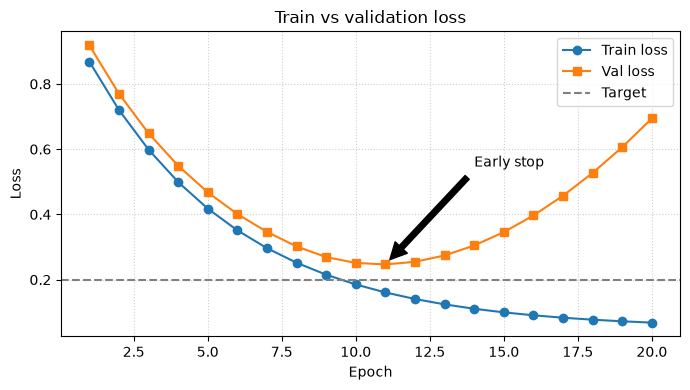

Best epoch: 11


In [ ]:
epochs = np.arange(1, 21)
train_loss = 1.0 * np.exp(-0.2 * epochs) + 0.05
val_loss = 1.0 * np.exp(-0.2 * epochs) + 0.1 + 0.004 * (epochs - 8).clip(0) ** 2

best_idx = np.argmin(val_loss)
best_epoch = epochs[best_idx]

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_loss, marker="o", label="Train loss")
plt.plot(epochs, val_loss, marker="s", label="Val loss")
plt.axhline(y=0.2, color="gray", linestyle="--", label="Target")
plt.annotate("Early stop", xy=(best_epoch, val_loss[best_idx]),
             xytext=(best_epoch + 3, val_loss[best_idx] + 0.3),
             arrowprops=dict(facecolor="black", shrink=0.05))
plt.title("Train vs validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right")
plt.tight_layout(); plt.show()
print("Best epoch:", best_epoch)

### SN1. Reproducible randomness

In [ ]:
names = ["Ada", "Grace", "Alan", "Linus", "Margaret", "Guido"]

rng_a = np.random.default_rng(7)
rng_b = np.random.default_rng(7)
rng_c = np.random.default_rng(8)
print("seed 7:", rng_a.random(3).round(4))
print("seed 7:", rng_b.random(3).round(4), "<- identical")
print("seed 8:", rng_c.random(3).round(4), "<- different")

rng = np.random.default_rng(42)
uniform = rng.random(5)
dice = rng.integers(1, 7, size=5)            # upper bound is EXCLUSIVE -> 1..6
shuffled = rng.permutation(10)
picked = rng.choice(names, size=3, replace=False)
print("uniform :", uniform.round(3))
print("dice    :", dice)
print("shuffled:", shuffled)
print("picked  :", picked)

seed 7: [0.6251 0.8972 0.7757]
seed 7: [0.6251 0.8972 0.7757] <- identical
seed 8: [0.327  0.9873 0.3187] <- different
uniform : [0.774 0.439 0.859 0.697 0.094]
dice    : [4 6 5 5 5]
shuffled: [4 0 2 8 5 1 7 6 9 3]
picked  : ['Guido' 'Alan' 'Margaret']


A generator object carries its own state, so each part of your code can have an independent, reproducible stream; a global seed is shared hidden state that any import or function call can disturb. Two generators with the same seed produce the same numbers, which is what makes experiments repeatable.

### SN2. The normal distribution

mean=169.92, std=8.05
within 1 sigma: 67.85%   (theory 68.27%)
within 2 sigma: 95.41%   (theory 95.45%)
within 3 sigma: 99.67%   (theory 99.73%)
5th / 50th / 95th percentiles: [156.6 169.9 183.1]


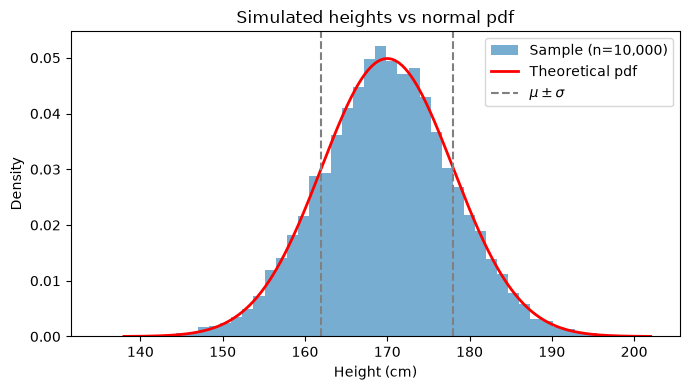

In [ ]:
rng = np.random.default_rng(42)
mu, sigma = 170, 8

heights = rng.normal(mu, sigma, size=10_000)
print(f"mean={heights.mean():.2f}, std={heights.std():.2f}")

for k_sig, theory in [(1, 68.27), (2, 95.45), (3, 99.73)]:
    frac = (np.abs(heights - mu) <= k_sig * sigma).mean() * 100   # mean of a boolean mask = fraction
    print(f"within {k_sig} sigma: {frac:.2f}%   (theory {theory}%)")

print("5th / 50th / 95th percentiles:", np.percentile(heights, [5, 50, 95]).round(1))

xs = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
pdf = np.exp(-(xs - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

plt.figure(figsize=(7, 4))
plt.hist(heights, bins=50, density=True, alpha=0.6, label="Sample (n=10,000)")
plt.plot(xs, pdf, "r-", lw=2, label="Theoretical pdf")
plt.axvline(mu - sigma, color="gray", linestyle="--", label=r"$\mu \pm \sigma$")
plt.axvline(mu + sigma, color="gray", linestyle="--")
plt.xlabel("Height (cm)"); plt.ylabel("Density"); plt.title("Simulated heights vs normal pdf")
plt.legend(); plt.tight_layout(); plt.show()

### SN3. The Central Limit Theorem

n= 1: std of means = 0.986   (theory 1/sqrt(n) = 1.000)
n= 2: std of means = 0.719   (theory 1/sqrt(n) = 0.707)
n=30: std of means = 0.182   (theory 1/sqrt(n) = 0.183)


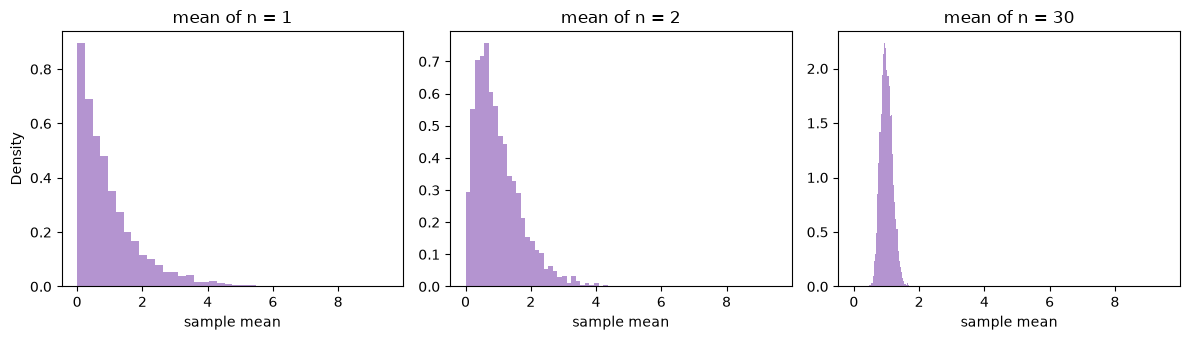

In [ ]:
rng = np.random.default_rng(42)
sizes = [1, 2, 30]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True)
for ax, n_obs in zip(axes, sizes):
    means = rng.exponential(scale=1.0, size=(5000, n_obs)).mean(axis=1)   # 5000 sample means at once
    ax.hist(means, bins=40, density=True, alpha=0.7, color="tab:purple")
    ax.set_title(f"mean of n = {n_obs}"); ax.set_xlabel("sample mean")
    print(f"n={n_obs:>2}: std of means = {means.std():.3f}   (theory 1/sqrt(n) = {1 / np.sqrt(n_obs):.3f})")
axes[0].set_ylabel("Density")
plt.tight_layout(); plt.show()

Even though each observation is heavily right-skewed, the distribution of the **sample mean** becomes more symmetric and bell-shaped as $n$ grows, and narrows like $1/\sqrt{n}$. This is why averages (and Gaussian-based confidence intervals) work for data that isn't Gaussian.

### SN4. Random walks

std of final positions: 30.3   (theory sqrt(1000) = 31.6)
fraction that ever hit +50: 0.116


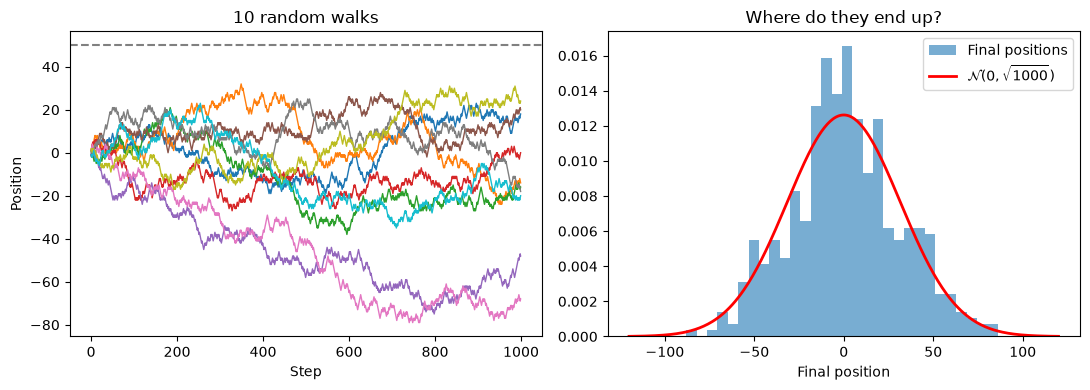

In [ ]:
rng = np.random.default_rng(42)
n_walkers, n_steps = 500, 1000

steps = rng.choice([-1, 1], size=(n_walkers, n_steps))
paths = steps.cumsum(axis=1)             # position after each step, per walker
final = paths[:, -1]

print(f"std of final positions: {final.std():.1f}   (theory sqrt(1000) = {np.sqrt(n_steps):.1f})")
print(f"fraction that ever hit +50: {(paths.max(axis=1) >= 50).mean():.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(paths[:10].T, lw=1)
ax1.axhline(50, color="gray", linestyle="--")
ax1.set_xlabel("Step"); ax1.set_ylabel("Position"); ax1.set_title("10 random walks")

xs = np.linspace(-120, 120, 300)
s = np.sqrt(n_steps)
ax2.hist(final, bins=30, density=True, alpha=0.6, label="Final positions")
ax2.plot(xs, np.exp(-xs ** 2 / (2 * s ** 2)) / (s * np.sqrt(2 * np.pi)), "r-", lw=2, label=r"$\mathcal{N}(0, \sqrt{1000})$")
ax2.set_xlabel("Final position"); ax2.set_title("Where do they end up?"); ax2.legend()
plt.tight_layout(); plt.show()

A sum of many independent ±1 steps is approximately normal (CLT again), with std $\sqrt{n}$, so the typical distance from the start grows like $\sqrt{\text{steps}}$, not linearly. By the reflection principle the chance of ever touching +50 is about $2P(S_n\ge 50)\approx 0.11$, which the simulation reproduces.

### SN5. Dice and `bincount`

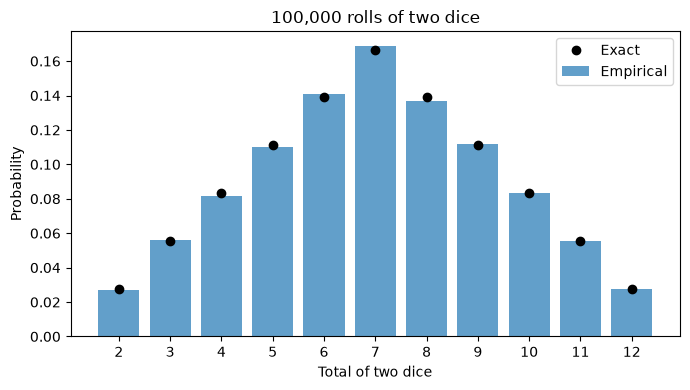

P(total >= 10): 0.1665   exact 0.1667
P(doubles)    : 0.1636   exact 0.1667
max |empirical - exact|: 0.0022


In [ ]:
rng = np.random.default_rng(42)
n_rolls = 100_000

d1 = rng.integers(1, 7, size=n_rolls)
d2 = rng.integers(1, 7, size=n_rolls)
total = d1 + d2

sums = np.arange(2, 13)
counts = np.bincount(total, minlength=13)[2:]     # drop the unused bins 0 and 1
emp = counts / n_rolls
exact = (6 - np.abs(sums - 7)) / 36

plt.figure(figsize=(7, 4))
plt.bar(sums, emp, alpha=0.7, label="Empirical")
plt.plot(sums, exact, "ko", label="Exact")
plt.xticks(sums); plt.xlabel("Total of two dice"); plt.ylabel("Probability")
plt.title("100,000 rolls of two dice"); plt.legend(); plt.tight_layout(); plt.show()

print(f"P(total >= 10): {(total >= 10).mean():.4f}   exact {6 / 36:.4f}")
print(f"P(doubles)    : {(d1 == d2).mean():.4f}   exact {6 / 36:.4f}")
print("max |empirical - exact|:", np.abs(emp - exact).max().round(4))

## Monte Carlo & π solutions

### SM1. Monte Carlo darts

pi_hat = 3.1354 +/- 0.0052   (true 3.1416, error 0.0062)


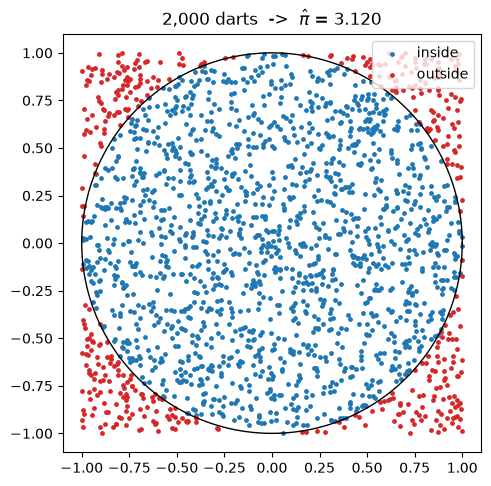

In [ ]:
rng = np.random.default_rng(42)
N = 100_000

pts = rng.uniform(-1, 1, size=(N, 2))
inside = (pts ** 2).sum(axis=1) <= 1          # x^2 + y^2 <= 1
p_hat = inside.mean()
pi_hat = 4 * p_hat
se = 4 * np.sqrt(p_hat * (1 - p_hat) / N)
print(f"pi_hat = {pi_hat:.4f} +/- {se:.4f}   (true {np.pi:.4f}, error {abs(pi_hat - np.pi):.4f})")

m = 2000
theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*pts[:m][inside[:m]].T, s=6, c="tab:blue", label="inside")
ax.scatter(*pts[:m][~inside[:m]].T, s=6, c="tab:red", label="outside")
ax.plot(np.cos(theta), np.sin(theta), "k-", lw=1)
ax.set_aspect("equal"); ax.set_title(f"{m:,} darts  ->  $\\hat\\pi$ = {4 * inside[:m].mean():.3f}")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

### SM2. Convergence of Monte Carlo

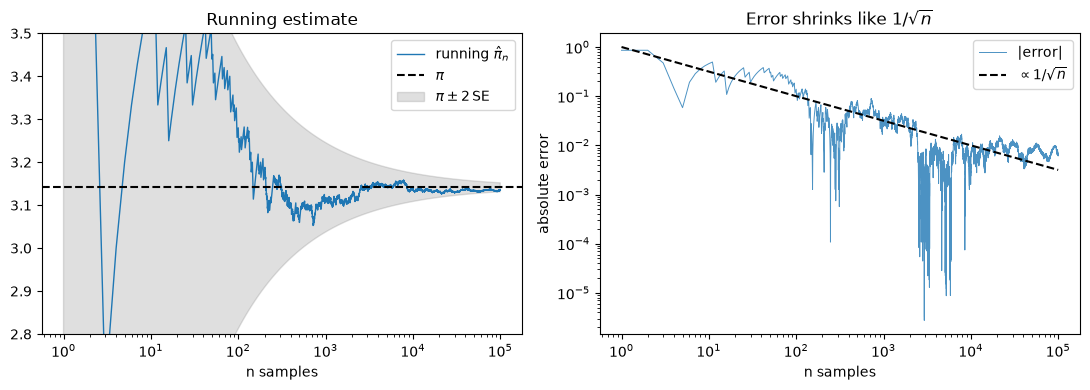

In [ ]:
n_axis = np.arange(1, N + 1)
running = 4 * np.cumsum(inside) / n_axis
se_n = 4 * np.sqrt(p_hat * (1 - p_hat) / n_axis)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogx(n_axis, running, lw=1, label=r"running $\hat\pi_n$")
ax1.axhline(np.pi, color="k", linestyle="--", label=r"$\pi$")
ax1.fill_between(n_axis, np.pi - 2 * se_n, np.pi + 2 * se_n, color="gray", alpha=0.25, label=r"$\pi \pm 2\,$SE")
ax1.set_ylim(2.8, 3.5); ax1.set_xlabel("n samples"); ax1.set_title("Running estimate"); ax1.legend()

err = np.abs(running - np.pi)
ax2.loglog(n_axis, err, lw=0.7, alpha=0.8, label="|error|")
ax2.loglog(n_axis, 1 / np.sqrt(n_axis), "k--", label=r"$\propto 1/\sqrt{n}$")
ax2.set_xlabel("n samples"); ax2.set_ylabel("absolute error"); ax2.set_title("Error shrinks like $1/\\sqrt{n}$"); ax2.legend()
plt.tight_layout(); plt.show()

The error scales as $1/\sqrt{n}$, so **100× more samples buys just one more correct decimal digit**. That slow rate is the price of Monte Carlo. Its strength is that the rate doesn't depend on dimension, which is why it dominates for high-dimensional integrals where grid-based methods are hopeless.

### SM3. The polygon method

 n_sides        lower        upper    lower_err
       6 3.0000000000 3.4641016151 0.1415926536
      12 3.1058285412 3.2153903092 0.0357641124
      24 3.1326286133 3.1596599421 0.0089640403
      48 3.1393502030 3.1460862151 0.0022424505
      96 3.1410319509 3.1427145996 0.0005607027
     192 3.1414524723 3.1418730500 0.0001401813
     384 3.1415576079 3.1416627471 0.0000350457
     768 3.1415838921 3.1416101766 0.0000087614
    1536 3.1415904632 3.1415970343 0.0000021904
    3072 3.1415921060 3.1415937488 0.0000005476
    6144 3.1415925167 3.1415929274 0.0000001369
   12288 3.1415926194 3.1415927220 0.0000000342
   24576 3.1415926450 3.1415926707 0.0000000086
   49152 3.1415926515 3.1415926579 0.0000000021
   98304 3.1415926531 3.1415926547 0.0000000005
pi trapped every time: True


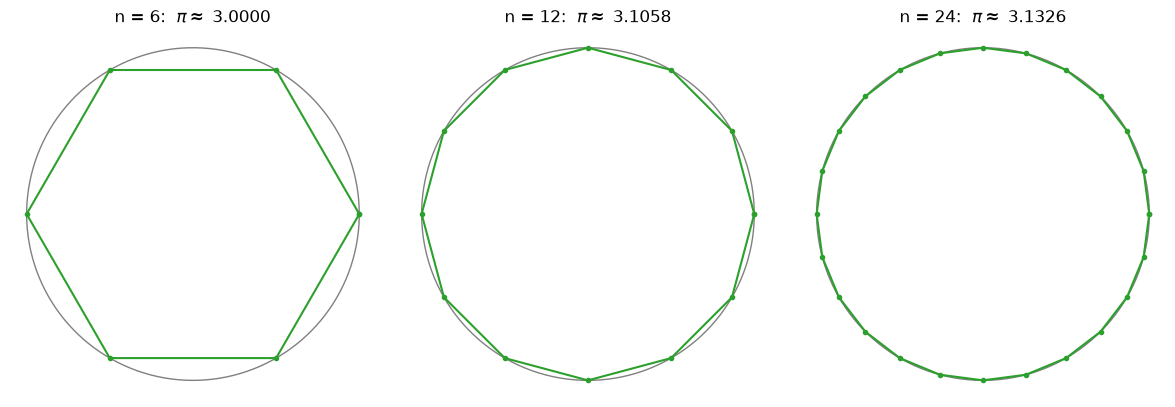

In [ ]:
n_sides, s = 6, 1.0
rows = []
for _ in range(15):
    lower = n_sides * s / 2                      # inscribed half-perimeter
    upper = n_sides * s / np.sqrt(4 - s ** 2)    # circumscribed half-perimeter
    rows.append((n_sides, lower, upper))
    s = s / np.sqrt(2 + np.sqrt(4 - s ** 2))     # side length after doubling n
    n_sides *= 2

poly = pd.DataFrame(rows, columns=["n_sides", "lower", "upper"])
poly["lower_err"] = np.pi - poly["lower"]
print(poly.to_string(index=False, float_format=lambda v: f"{v:.10f}"))
print("pi trapped every time:", bool(((poly["lower"] < np.pi) & (np.pi < poly["upper"])).all()))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
theta = np.linspace(0, 2 * np.pi, 300)
for ax, n_poly in zip(axes, [6, 12, 24]):
    ang = np.linspace(0, 2 * np.pi, n_poly + 1)            # n+1 points closes the polygon
    ax.plot(np.cos(theta), np.sin(theta), color="gray", lw=1)
    ax.plot(np.cos(ang), np.sin(ang), "o-", color="tab:green", ms=3)
    half_perim = n_poly * 2 * np.sin(np.pi / n_poly) / 2
    ax.set_title(f"n = {n_poly}:  $\\pi \\approx$ {half_perim:.4f}"); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.show()

Each doubling cuts the error by roughly 4×, i.e. error $\propto 1/n^2$. With ~100k sides we already have 9 correct digits, and the sequence is **deterministic with guaranteed bounds**. (The naive form $\sqrt{2-\sqrt{4-s^2}}$ subtracts two nearly equal numbers once $s$ is small and silently loses accuracy, which is why we use the rationalised version.)

### SM4. The Leibniz series

       10 terms: 3.04183962   error 9.98e-02
      100 terms: 3.13159290   error 1.00e-02
    1,000 terms: 3.14059265   error 1.00e-03
   10,000 terms: 3.14149265   error 1.00e-04
  100,000 terms: 3.14158265   error 1.00e-05
1,000,000 terms: 3.14159165   error 1.00e-06


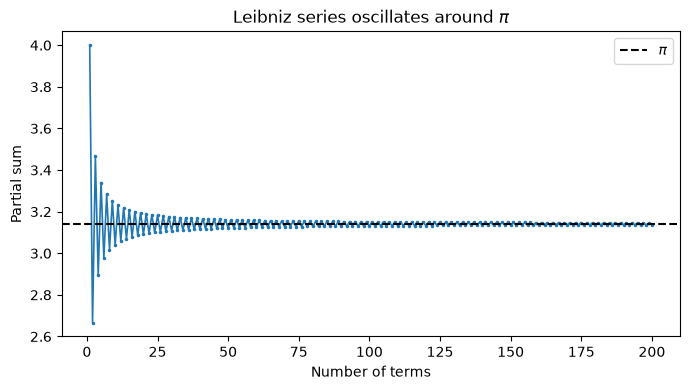

In [ ]:
N_terms = 1_000_000
k = np.arange(N_terms)

leibniz = 4 * np.cumsum((-1.0) ** k / (2 * k + 1))

for p in range(1, 7):
    n_t = 10 ** p
    print(f"{n_t:>9,} terms: {leibniz[n_t - 1]:.8f}   error {abs(leibniz[n_t - 1] - np.pi):.2e}")

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, 201), leibniz[:200], lw=1.2, marker=".", ms=3)
plt.axhline(np.pi, color="k", linestyle="--", label=r"$\pi$")
plt.xlabel("Number of terms"); plt.ylabel("Partial sum"); plt.title("Leibniz series oscillates around $\\pi$")
plt.legend(); plt.tight_layout(); plt.show()

The partial sums alternate above and below $\pi$ and the error is about $1/n$: ten times more terms gives one more digit. Better than Monte Carlo ($1/\sqrt{n}$), but far slower than the polygon method.

### SM5. Head-to-head

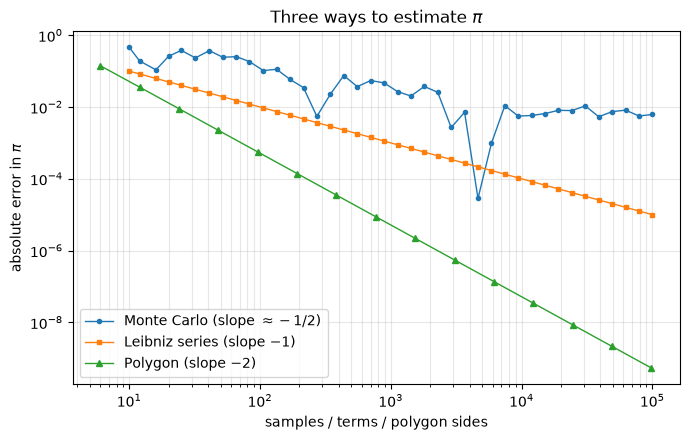

In [ ]:
ns = np.unique(np.logspace(1, 5, 40).astype(int))
floor = 1e-16

mc_err = np.maximum(np.abs(running[ns - 1] - np.pi), floor)
lb_err = np.maximum(np.abs(leibniz[ns - 1] - np.pi), floor)
poly_err = np.maximum(np.abs(poly["lower"] - np.pi), floor)

plt.figure(figsize=(7, 4.5))
plt.loglog(ns, mc_err, "o-", ms=3, lw=1, label=r"Monte Carlo (slope $\approx -1/2$)")
plt.loglog(ns, lb_err, "s-", ms=3, lw=1, label=r"Leibniz series (slope $-1$)")
plt.loglog(poly["n_sides"], poly_err, "^-", ms=4, lw=1, label=r"Polygon (slope $-2$)")
plt.xlabel("samples / terms / polygon sides"); plt.ylabel("absolute error in $\\pi$")
plt.title("Three ways to estimate $\\pi$"); plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

**Polygon** (slope −2) beats **Leibniz** (−1) beats **Monte Carlo** (−½). For a 1-D problem with a smooth, known structure, deterministic methods win by orders of magnitude. Monte Carlo is the method of choice when the integrand lives in many dimensions, has no closed form, or you only have a simulator. Then its dimension-independent $1/\sqrt{n}$ rate and built-in error bar (the standard error) are what matter.

### S8. Generate & scale

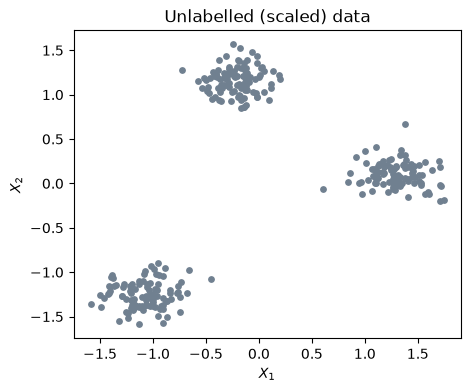

In [ ]:
X_raw, y_true = make_blobs(n_samples=300, centers=3, n_features=2, random_state=42)
X_s = StandardScaler().fit_transform(X_raw)

plt.figure(figsize=(5, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], s=15, c="slategray")
plt.title("Unlabelled (scaled) data"); plt.xlabel("$X_1$"); plt.ylabel("$X_2$")
plt.show()

### S9. Lloyd's K-Means from scratch

In [ ]:
def kmeans_scratch(X, K, max_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    labels = rng.integers(0, K, size=n)          # Step 1: random assignment

    for _ in range(max_iter):
        # (a) centroids; re-seed an empty cluster with a random point
        centroids = np.array([
            X[labels == k].mean(axis=0) if np.any(labels == k) else X[rng.integers(n)]
            for k in range(K)
        ])
        # (b) squared Euclidean distance to every centroid -> (n, K)
        dists = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        new_labels = dists.argmin(axis=1)
        if np.array_equal(new_labels, labels):     # converged
            break
        labels = new_labels

    # final centroids & inertia
    centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])
    inertia = ((X - centroids[labels]) ** 2).sum()
    return labels, centroids, inertia

labels, cents, inertia = kmeans_scratch(X_s, K=3, seed=0)
print("Inertia (seed 0):", round(inertia, 3))

Inertia (seed 0): 18.263


### S10. Random restarts vs scikit-learn

Inertia across seeds: min=18.263, max=184.990
Best scratch inertia: 18.263
sklearn inertia:      18.263


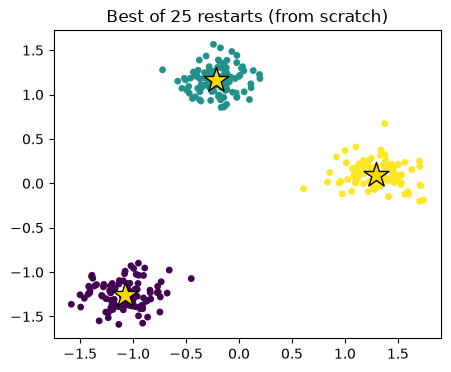

In [ ]:
results = [kmeans_scratch(X_s, K=3, seed=s) for s in range(25)]
inertias_seeds = np.array([r[2] for r in results])
best_labels, best_cents, best_inertia = results[int(inertias_seeds.argmin())]

print(f"Inertia across seeds: min={inertias_seeds.min():.3f}, max={inertias_seeds.max():.3f}")
print(f"Best scratch inertia: {best_inertia:.3f}")

km = KMeans(n_clusters=3, n_init=25, random_state=42).fit(X_s)
print(f"sklearn inertia:      {km.inertia_:.3f}")

plt.figure(figsize=(5, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=best_labels, cmap="viridis", s=15)
plt.scatter(best_cents[:, 0], best_cents[:, 1], marker="*", s=350, c="gold", edgecolor="black")
plt.title("Best of 25 restarts (from scratch)")
plt.show()

Even on clean blobs, some seeds get stuck in a poor local optimum (here roughly 10× worse inertia, typically two blobs merged and one split). Keeping the best of many restarts fixes this, which is exactly why ISLP recommends `n_init = 20–50`. Your best scratch result should match sklearn.

### S11. Elbow & silhouette

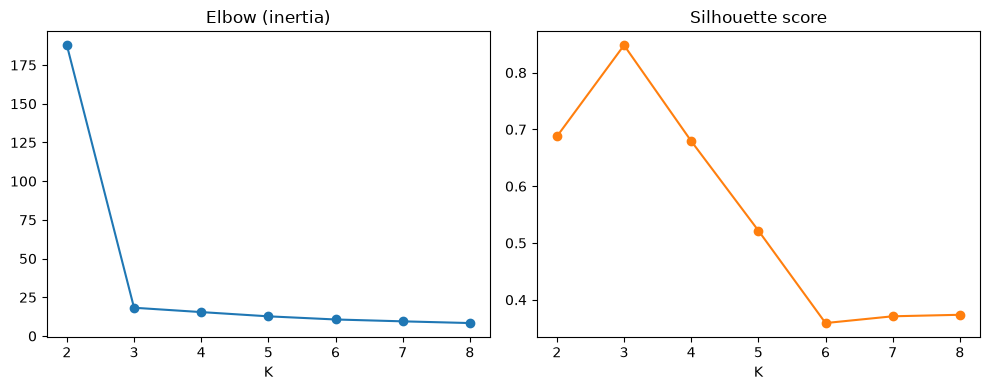

Best K by silhouette: 3


In [ ]:
Ks = list(range(2, 9))
inertias, sils = [], []
for k in Ks:
    m = KMeans(n_clusters=k, n_init=25, random_state=42).fit(X_s)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(X_s, m.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(Ks, inertias, marker="o"); ax1.set_title("Elbow (inertia)"); ax1.set_xlabel("K")
ax2.plot(Ks, sils, marker="o", color="tab:orange"); ax2.set_title("Silhouette score"); ax2.set_xlabel("K")
plt.tight_layout(); plt.show()
print("Best K by silhouette:", Ks[int(np.argmax(sils))])

**K = 3:** the elbow is at 3 and the silhouette peaks there. Inertia alone can't choose K because it **always decreases** as K grows (K = n gives inertia 0), so you look for diminishing returns or use a score like the silhouette that penalises splitting real clusters.

### S12. PCA from scratch

PVE (scratch): [0.5618 0.3496 0.0308 0.0298 0.028 ]
PVE (sklearn): [0.5618 0.3496 0.0308 0.0298 0.028 ]


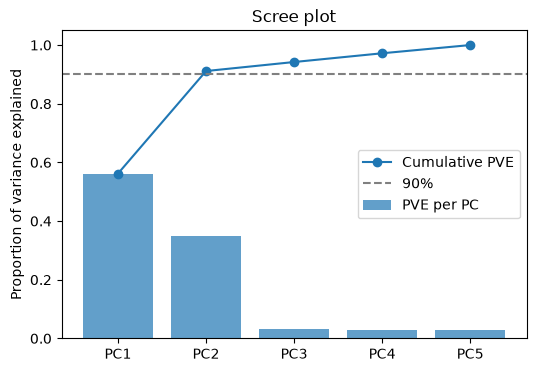

Components needed for 90%: 2


In [ ]:
rng = np.random.default_rng(42)
latent = rng.normal(size=(500, 2))
mix = rng.normal(size=(2, 5))
X5 = latent @ mix + 0.3 * rng.normal(size=(500, 5))

Xc = X5 - X5.mean(axis=0)
cov = (Xc.T @ Xc) / (Xc.shape[0] - 1)
eigvals, eigvecs = np.linalg.eigh(cov)          # ascending for symmetric matrices
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

pve = eigvals / eigvals.sum()
cum_pve = np.cumsum(pve)

print("PVE (scratch):", pve.round(4))
print("PVE (sklearn):", PCA().fit(X5).explained_variance_ratio_.round(4))

scores = Xc @ eigvecs      # principal component scores z_ik

pcs = [f"PC{i+1}" for i in range(5)]
plt.figure(figsize=(6, 4))
plt.bar(pcs, pve, alpha=0.7, label="PVE per PC")
plt.plot(pcs, cum_pve, marker="o", color="tab:blue", label="Cumulative PVE")
plt.axhline(0.9, linestyle="--", color="gray", label="90%")
plt.ylabel("Proportion of variance explained"); plt.title("Scree plot")
plt.legend(); plt.show()
print("Components needed for 90%:", int(np.argmax(cum_pve >= 0.9)) + 1)

The data was built from **2 latent factors** plus noise, so PC1 and PC2 carry nearly all the variance and the elbow sits at 2.

### S13. Why scaling matters

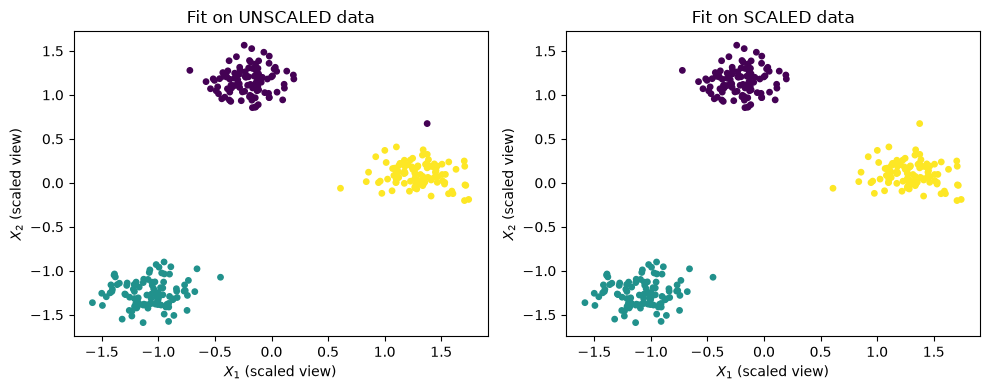

In [ ]:
X_bad = X_raw.copy()
X_bad[:, 1] *= 1000

lab_unscaled = KMeans(n_clusters=3, n_init=25, random_state=42).fit_predict(X_bad)
X_bad_s = StandardScaler().fit_transform(X_bad)
lab_scaled = KMeans(n_clusters=3, n_init=25, random_state=42).fit_predict(X_bad_s)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(X_bad_s[:, 0], X_bad_s[:, 1], c=lab_unscaled, s=15, cmap="viridis")
ax1.set_title("Fit on UNSCALED data")
ax2.scatter(X_bad_s[:, 0], X_bad_s[:, 1], c=lab_scaled, s=15, cmap="viridis")
ax2.set_title("Fit on SCALED data")
for ax in (ax1, ax2): ax.set_xlabel("$X_1$ (scaled view)"); ax.set_ylabel("$X_2$ (scaled view)")
plt.tight_layout(); plt.show()

Without scaling, Euclidean distance is dominated by the ×1000 feature, so K-Means effectively clusters on $X_2$ alone and slices the data into horizontal bands. After scaling, both features contribute equally and the true blobs are recovered.

### Bonus: Make your own modern art masterpiece!

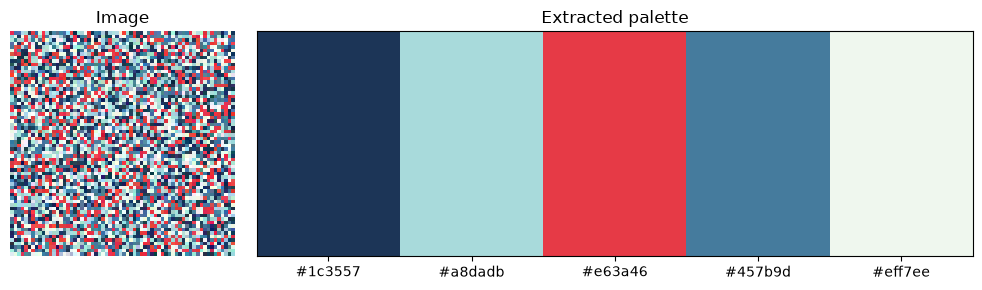

In [ ]:
rng = np.random.default_rng(42)
# Synthetic image: 5 colour regions plus noise (swap for plt.imread("poster.jpg")[..., :3] * 255)
base = np.array([[230, 57, 70], [241, 250, 238], [168, 218, 220], [69, 123, 157], [29, 53, 87]])
region = rng.integers(0, 5, size=(64, 64))
img = np.clip(base[region] + rng.normal(0, 12, size=(64, 64, 3)), 0, 255)

pixels = img.reshape(-1, 3)
pal = KMeans(n_clusters=5, n_init=10, random_state=42).fit(pixels)
colours = pal.cluster_centers_.round().astype(int)
hexes = ["#{:02x}{:02x}{:02x}".format(*c) for c in colours]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [1, 3]})
ax1.imshow(img.astype(np.uint8)); ax1.axis("off"); ax1.set_title("Image")
ax2.imshow(colours[None, :, :].astype(np.uint8), aspect="auto")
ax2.set_xticks(range(5)); ax2.set_xticklabels(hexes); ax2.set_yticks([]); ax2.set_title("Extracted palette")
plt.tight_layout(); plt.show()

## La fin. 🎉